# The Lesion Across Sections

**C-Stroke · case HB02CV · reference notebook 3 of 4**

A single slide shows the lesion in one plane. The C-Stroke blocks were sectioned completely, and the infarct is outlined on H&E sections along the three left-hemisphere blocks (313, 314 and 315). Seven IHC markers are annotated on the sections in between. Followed through the blocks, these annotations describe the lesion in three dimensions and show how the tissue response is organised around it.

This notebook shows how to work with annotations across sections:

1. Measure the infarct on every annotated section and follow its area along each block.
2. Estimate the infarct volume per block.
3. Map the infarct footprint and reconstruct its 3D shape.
4. Follow the burden of each IHC marker along the blocks and compare it with the infarct.
5. Profile every marker by distance from the infarct border, pooled over all slides.

It uses `AnnotationSeries` and `SectionAnnotation` from `pathology_utils.py`, and `SlideCatalog` and `SlideHelper` from `slide_utils.py`. See `slide_catalog_and_images.ipynb` and `pathology_annotations.ipynb` for the basics.

**Runtime:** about 10 minutes on a CPU for a first run (several hundred annotation files and slide overviews are downloaded), and about 2 minutes from the cache.

## 1. Setup

The notebook uses the helper modules of this repository. In a local clone they are found automatically. On Google Colab, Kaggle or any other fresh environment, the cell below clones the repository first. All data are read from the C-Stroke platform at `https://c-stroke.humanbrain.in` and cached under `~/.cache/cstroke`.

In [1]:
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/24f2007780/stroke_utils.git"

# Use the local repository (this notebook's parent folder) if present; otherwise clone it.
root = next((p for p in (Path.cwd(), Path.cwd().parent, Path.cwd() / "stroke_utils")
             if (p / "slide_utils.py").exists()), None)
if root is None:
    subprocess.run(["git", "clone", "-q", REPO_URL], check=True)
    root = Path.cwd() / "stroke_utils"
sys.path.insert(0, str(root))
print("Helper modules from", root)

Helper modules from /home/antareep/workspace/stroke_notebook/stroke_utils


In [2]:
import warnings
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from scipy import stats

import display_utils as du
from pathology_utils import AnnotationSeries
from slide_utils import BLOCKS, MARKERS, Region, SlideCatalog, SlideHelper, tissue_mask

du.set_style()
pd.set_option("display.float_format", "{:.2f}".format)

INFARCT_BLOCKS = [313, 314, 315]            # blocks with infarct annotations on H&E
IHC_MARKERS = ["FIB", "APP", "CD68", "GAP43", "HIF1a", "GFAP", "CD34"]
MESH_BLOCK = 313                            # block reconstructed in 3D (Section 4)

# Distance profiles (Section 6)
MAX_INFARCT_GAP_UM = 500                    # IHC slide and infarct-annotated H&E section at most this far apart
ANALYSIS_DOWNSAMPLE = 5                     # ~32 um per pixel
BAND_EDGES_MM = np.arange(-6.0, 16.01, 0.5)
MIN_SLIDES_PER_BAND = 5
N_BOOTSTRAP = 1000
RANDOM_SEED = 7

catalog = SlideCatalog()
BLOCK_COLORS = dict(zip(INFARCT_BLOCKS, ["#2a78d6", "#eb6834", "#1baf7a"]))

## 2. The infarct along each block

`AnnotationSeries(block, "HE")` collects every infarct-annotated H&E section of a block. `load()` downloads them in parallel, and `table()` gives one row per section with its position along the block and the annotated area. Dividing by the tissue area of the section, from `SlideHelper.get_tissue_area_mm2`, gives the share of the section that is infarcted.

In [3]:
infarct = {b: AnnotationSeries(b, "HE", catalog=catalog).load() for b in INFARCT_BLOCKS}
for b, series in infarct.items():
    print(series, "| unavailable files:", series.missing or "none")


def tissue_areas(block, stain, sections):
    helper = SlideHelper(block, stain, catalog=catalog)
    with ThreadPoolExecutor(max_workers=8) as ex:
        return dict(zip(sections, ex.map(helper.get_tissue_area_mm2, sections)))


infarct_table = []
for b, series in infarct.items():
    t = series.table()
    areas = tissue_areas(b, "HE", t.section.tolist())
    t["tissue_mm2"] = t.section.map(areas)
    t["infarct_share"] = t.area_mm2 / t.tissue_mm2
    t.insert(0, "block", b)
    infarct_table.append(t)
infarct_table = pd.concat(infarct_table, ignore_index=True)
infarct_table[["block", "section", "position_mm", "polygons", "area_mm2", "tissue_mm2", "infarct_share"]].head()

AnnotationSeries(block 313, HE, 39 sections, 39 loaded) | unavailable files: none
AnnotationSeries(block 314, HE, 46 sections, 46 loaded) | unavailable files: none
AnnotationSeries(block 315, HE, 29 sections, 29 loaded) | unavailable files: none


,block,section,position_mm,polygons,area_mm2,tissue_mm2,infarct_share
0,313,368,7.36,1,37.77,6520.01,0.01
1,313,398,7.96,1,33.30,6838.27,0.00
2,313,416,8.32,1,33.47,6957.30,0.00
3,313,440,8.80,1,30.04,7332.18,0.00
4,313,458,9.16,1,30.85,7419.85,0.00


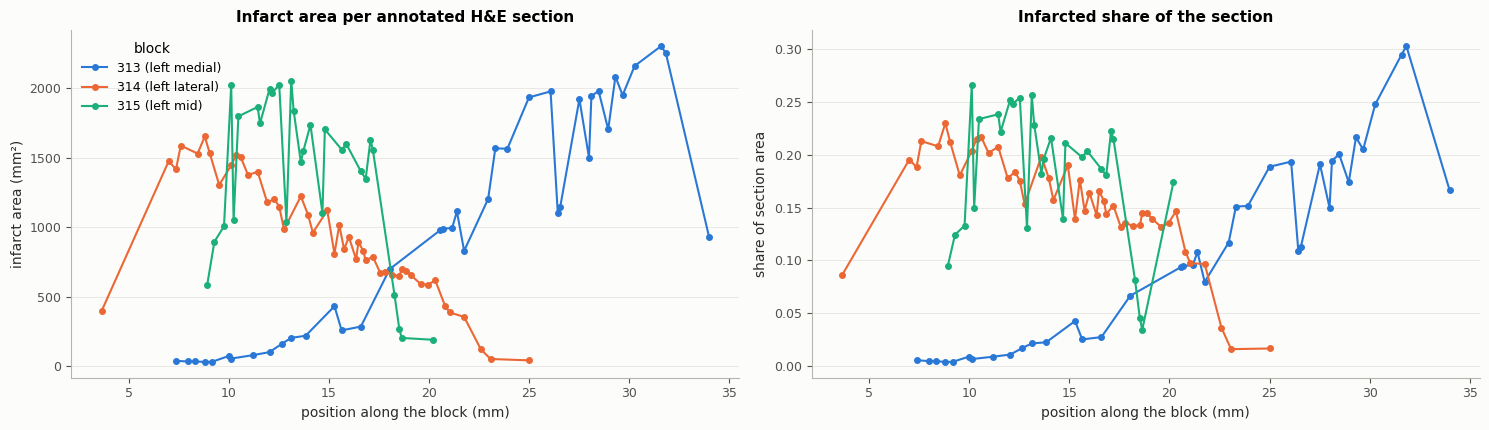

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.4))
for b in INFARCT_BLOCKS:
    t = infarct_table[infarct_table.block == b]
    for ax, col in ((ax1, "area_mm2"), (ax2, "infarct_share")):
        ax.plot(t.position_mm, t[col], "o-", ms=4, lw=1.5, color=BLOCK_COLORS[b], label=f"{b} ({BLOCKS[b]})")
ax1.set_ylabel("infarct area (mm²)")
ax1.set_title("Infarct area per annotated H&E section")
ax2.set_ylabel("share of section area")
ax2.set_title("Infarcted share of the section")
for ax in (ax1, ax2):
    ax.set_xlabel("position along the block (mm)")
    ax.grid(axis="y")
ax1.legend(title="block")
plt.tight_layout()
plt.show()

## 3. Infarct volume

`volume_mm3()` integrates the infarct area over position along the block (trapezoid rule). Between annotated sections the area is interpolated linearly, so the estimate is as good as the sampling. The table lists the number of annotated sections and the largest gap between them for each block.

In [5]:
volumes = pd.DataFrame([{
    "block": b, "position": BLOCKS[b], "annotated sections": len(s.annotations),
    "span (mm)": np.ptp(np.array(sorted(s.annotations)) * 0.02),
    "largest gap (mm)": np.diff(sorted(s.annotations)).max() * 0.02,
    "largest area (mm²)": infarct_table[infarct_table.block == b].area_mm2.max(),
    "volume (mm³)": s.volume_mm3()} for b, s in infarct.items()])
volumes.loc[len(volumes)] = ["all", "", volumes["annotated sections"].sum(), np.nan, np.nan, np.nan,
                             volumes["volume (mm³)"].sum()]
volumes

,block,position,annotated sections,span (mm),largest gap (mm),largest area (mm²),volume (mm³)
0,313,left medial,39,26.64,2.52,2303.99,26461.87
1,314,left lateral,46,21.36,3.36,1653.28,18595.73
2,315,left mid,29,11.28,1.56,2055.95,14421.34
3,all,,114,NaN,NaN,NaN,59478.94


The total, roughly 60 mL of infarcted tissue in the three left-hemisphere blocks, is a histological estimate. Fixation and processing shrink tissue, and the outline marks the infarct as recognised on H&E. `mri_reference_space.ipynb` compares it with the lesion volumes measured on the MRI.

## 4. The shape of the infarct

All sections of a block share one canvas, so the infarct outlines of a block can be stacked. Two views summarise the stack:

* **Footprint.** For every point of the canvas, the share of annotated sections in which it lies inside the infarct, drawn over a Nissl overview of the block. This 2D summary shows where the infarct is persistent and where it appears on only a few sections.
* **3D surface.** `AnnotationSeries.to_mesh()` interpolates the outlines between sections (shape-based interpolation of signed distance maps) and extracts a surface with marching cubes. Distances are scaled equally on all axes.

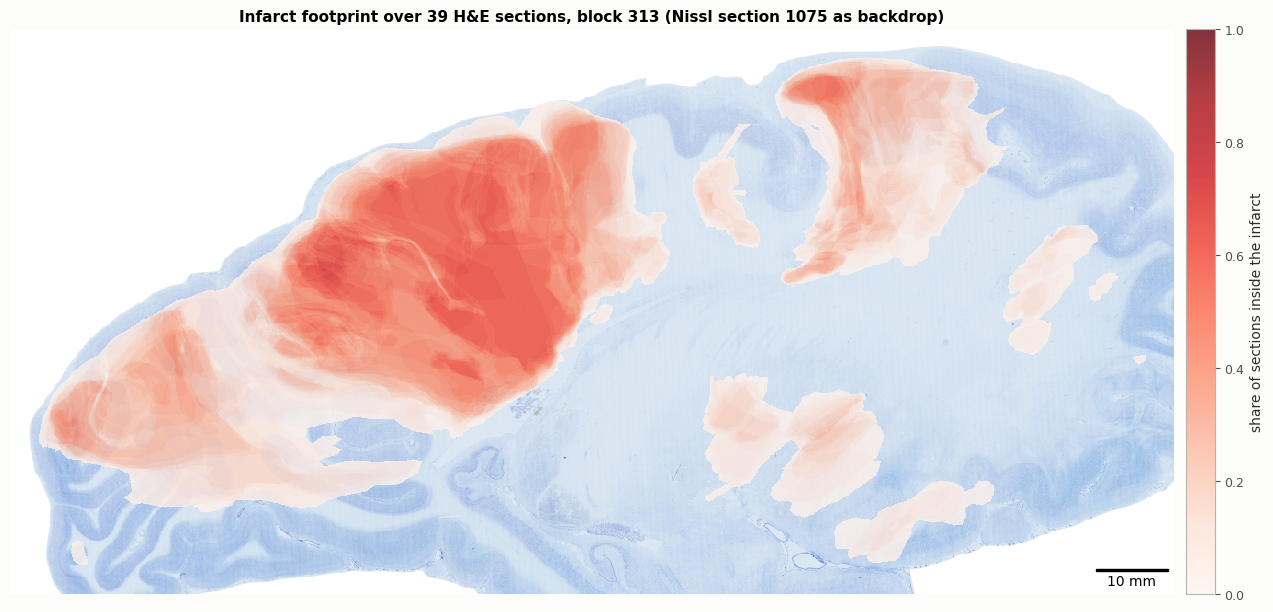

In [6]:
series = infarct[MESH_BLOCK]
bounds = np.array([a.union().bounds for a in series.annotations.values()])
pad = 4000
x0, y0 = bounds[:, 0].min() - pad, bounds[:, 1].min() - pad
x1, y1 = bounds[:, 2].max() + pad, bounds[:, 3].max() + pad
grid = Region(x0, y0, 128.0, (int((y1 - y0) / 128), int((x1 - x0) / 128)))      # 128 um per pixel

stack, positions = series.to_stack(grid)
footprint = stack.mean(axis=0)
nissl = SlideHelper(MESH_BLOCK, "N", catalog=catalog)
mid = nissl.get_section_numbers()[int(np.argmin(np.abs(np.array(nissl.get_section_numbers()) * 0.02 - np.median(positions))))]
backdrop, back_region = nissl.get_region(mid, x0, y0, x1 - x0, y1 - y0, downsample=7)

fig, ax = plt.subplots(figsize=(13, 6.2))
du.show_image(ax, backdrop, back_region, f"Infarct footprint over {len(stack)} H&E sections, block {MESH_BLOCK} "
              f"(Nissl section {mid} as backdrop)", bar_mm=10)
h = ax.imshow(np.ma.masked_equal(footprint, 0), cmap="Reds", vmin=0, vmax=1, alpha=0.8,
              extent=(0, backdrop.shape[1], backdrop.shape[0], 0))
plt.colorbar(h, ax=ax, fraction=0.025, pad=0.01, label="share of sections inside the infarct")
plt.tight_layout()
plt.show()

172784 triangles; enclosed volume of the interpolated stack: 25669 mm3


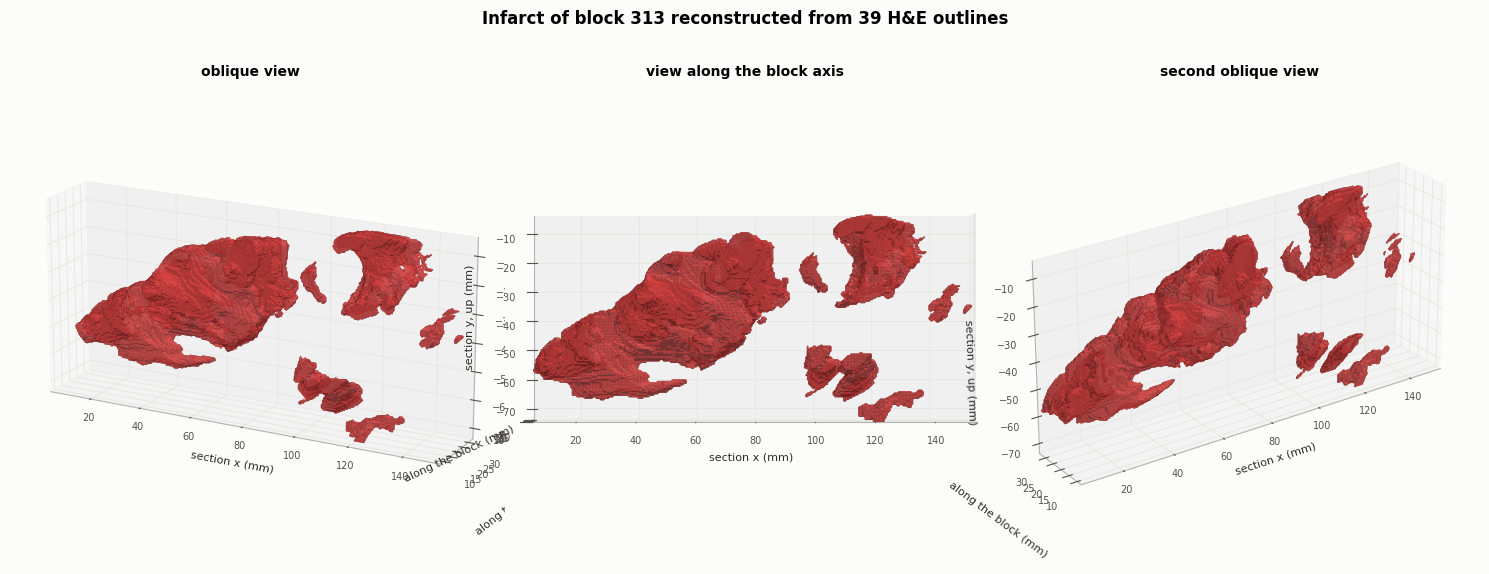

In [7]:
coarse = Region(x0, y0, 256.0, (int((y1 - y0) / 256), int((x1 - x0) / 256)))     # 256 um per pixel
vertices, faces = series.to_mesh(coarse, z_step_mm=0.25, step_size=2)
xyz = np.column_stack([vertices[:, 2], vertices[:, 0], -vertices[:, 1]])        # image x, block position, image up
print(f"{len(faces)} triangles; enclosed volume of the interpolated stack: "
      f"{series.interpolate(coarse)[0].sum() * 0.25 * (coarse.mpp / 1000) ** 2:.0f} mm3")

fig = plt.figure(figsize=(15, 6.2))
for k, (elev, azim, title) in enumerate([(18, -62, "oblique view"), (0, -90, "view along the block axis"),
                                          (25, -125, "second oblique view")]):
    ax = fig.add_subplot(1, 3, k + 1, projection="3d")
    du.show_mesh(ax, xyz, faces, elev=elev, azim=azim)
    ax.set_xlabel("section x (mm)", fontsize=8, labelpad=8)
    ax.set_ylabel("along the block (mm)", fontsize=8, labelpad=8)
    ax.set_zlabel("section y, up (mm)", fontsize=8, labelpad=6)
    ax.tick_params(labelsize=7)
    ax.set_title(title, fontsize=10)
plt.suptitle(f"Infarct of block {MESH_BLOCK} reconstructed from {len(series.annotations)} H&E outlines",
             fontweight="bold")
plt.tight_layout()
plt.show()

The block axis runs left–right in the brain: the blocks are slabs along that axis, and each section is a near-sagittal plane. The other two axes are the image axes of the sections, with "up" as displayed in the slide images. *To explore:* set `MESH_BLOCK = 314` or `315`.

## 5. Marker burden along the blocks

The same series approach works for every IHC marker. For each annotated IHC section, the **burden** is the annotated share of the section's tissue. The panels follow the burden of each marker (dots) along the three blocks, with the infarcted share of the H&E sections (grey) as reference.

In [8]:
def marker_table(block, marker):
    series = AnnotationSeries(block, marker, catalog=catalog).load()
    if not series.annotations:
        return pd.DataFrame()
    t = series.table()
    t["tissue_mm2"] = t.section.map(tissue_areas(block, "IHC", t.section.tolist()))
    t["burden"] = t.area_mm2 / t.tissue_mm2
    t["block"], t["marker"] = block, marker
    return t


burden = pd.concat([marker_table(b, m) for b in INFARCT_BLOCKS for m in IHC_MARKERS], ignore_index=True)
burden.groupby(["marker", "block"]).size().unstack()

block,313,314,315
marker,,,
APP,10,3,2
CD34,11,6,6
CD68,16,26,9
FIB,23,16,12
GAP43,12,2,2
GFAP,20,15,11
HIF1a,13,27,2


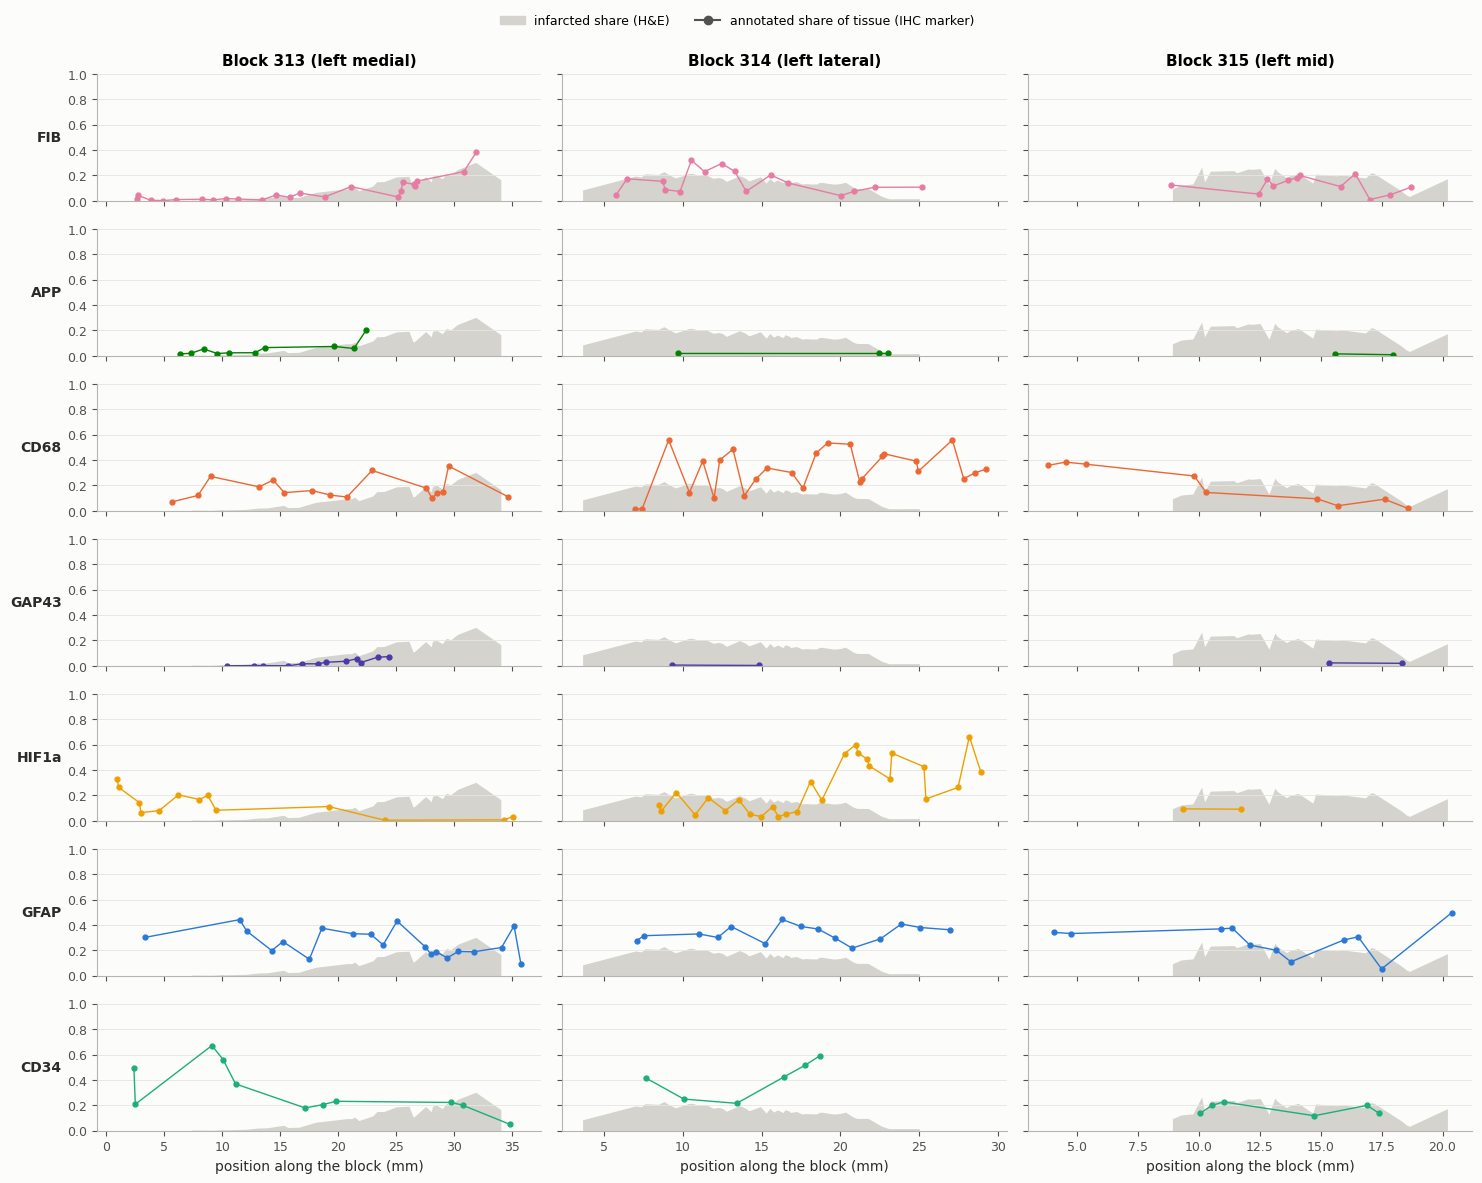

In [9]:
fig, axes = plt.subplots(len(IHC_MARKERS), len(INFARCT_BLOCKS), figsize=(15, 1.55 * len(IHC_MARKERS) + 1),
                         sharex="col", sharey="row")
for c, b in enumerate(INFARCT_BLOCKS):
    inf = infarct_table[infarct_table.block == b]
    for r, m in enumerate(IHC_MARKERS):
        ax = axes[r, c]
        ax.fill_between(inf.position_mm, inf.infarct_share, color="#d4d3cd", lw=0, step=None)
        t = burden[(burden.block == b) & (burden.marker == m)].sort_values("position_mm")
        ax.plot(t.position_mm, t.burden, "o-", ms=3.5, lw=1, color=du.MARKER_COLORS[m])
        ax.set_ylim(0, 1)
        if c == 0:
            ax.set_ylabel(m, rotation=0, ha="right", va="center", fontweight="bold")
        if r == 0:
            ax.set_title(f"Block {b} ({BLOCKS[b]})")
        ax.grid(axis="y")
for ax in axes[-1]:
    ax.set_xlabel("position along the block (mm)")
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color="#d4d3cd", label="infarcted share (H&E)"),
                    Line2D([], [], marker="o", color="#52514e", label="annotated share of tissue (IHC marker)")],
           loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.0))
plt.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

To summarise each panel in one number, the infarcted share is interpolated to the position of every IHC section. Spearman's ρ then measures whether the marker's burden rises and falls with the infarct along the block.

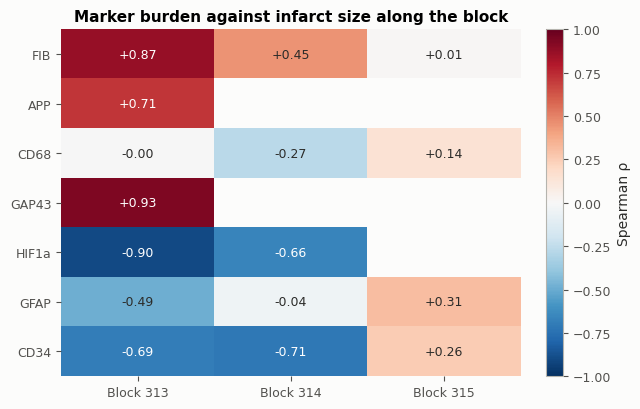

In [10]:
rows = []
for (m, b), t in burden.groupby(["marker", "block"]):
    inf = infarct_table[infarct_table.block == b].sort_values("position_mm")
    inside = t[(t.position_mm >= inf.position_mm.min()) & (t.position_mm <= inf.position_mm.max())]
    if len(inside) < 5:
        continue
    reference = np.interp(inside.position_mm, inf.position_mm, inf.infarct_share)
    rows.append({"marker": m, "block": b, "sections": len(inside),
                 "rho": stats.spearmanr(inside.burden, reference)[0]})
coupling = pd.DataFrame(rows).pivot(index="marker", columns="block", values="rho").reindex(IHC_MARKERS)

fig, ax = plt.subplots(figsize=(6.5, 4.2))
h = ax.imshow(coupling.values, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")  # blank: too few sections
ax.set_xticks(range(coupling.shape[1]), [f"Block {b}" for b in coupling.columns])
ax.set_yticks(range(coupling.shape[0]), coupling.index)
for (r, c), v in np.ndenumerate(coupling.values):
    if np.isfinite(v):
        ax.text(c, r, f"{v:+.2f}", ha="center", va="center", fontsize=9, color="white" if abs(v) > 0.6 else "#2b2b29")
plt.colorbar(h, ax=ax, fraction=0.05, label="Spearman ρ")
ax.set_title("Marker burden against infarct size along the block")
ax.spines[:].set_visible(False)
plt.tight_layout()
plt.show()

In block 313, where the infarct grows steadily along the block, fibrinogen, APP and GAP43 burden rise with it, while HIF1α, CD34 and GFAP burden fall. That is the same split between processes concentrated in the infarct and processes depleted inside it that Section 6 resolves spatially. Blocks 314 and 315 show weaker or mixed relations, and several cells rest on fewer than ten sections. Blank cells have fewer than five IHC sections within the range of the infarct annotations.

## 6. The tissue response around the infarct

Section 5 compares whole sections. The spatial organisation becomes visible when every pixel is placed relative to the infarct border.

* Each annotated IHC slide is paired with the nearest infarct-annotated H&E section, at most `MAX_INFARCT_GAP_UM` away.
* The infarct outline gives every tissue pixel a signed distance to the border (negative inside; see `pathology_annotations.ipynb`).
* In 0.5 mm distance bands, the share of tissue covered by the marker's annotation is the marker's *coverage* at that distance.
* Profiles are averaged over slides, with 95% bootstrap intervals obtained by resampling slides.

In [11]:
ihc = catalog.find(block=INFARCT_BLOCKS, stain="IHC", annotated=True)
ihc = ihc[ihc.marker.isin(IHC_MARKERS)].copy()
nearest = [catalog.nearest(b, s, "HE", annotated=True) for b, s in zip(ihc.block, ihc.section)]
ihc["infarct_section"] = [n.section for n in nearest]
ihc["gap_um"] = [abs(n.gap_sections) * 20 for n in nearest]
pairs = ihc[ihc.gap_um <= MAX_INFARCT_GAP_UM].reset_index(drop=True)
print(f"{len(pairs)} IHC slides have an infarct outline within {MAX_INFARCT_GAP_UM} um")
pairs.groupby(["marker", "block"]).size().unstack(fill_value=0).reindex(IHC_MARKERS)

192 IHC slides have an infarct outline within 500 um


block,313,314,315
marker,,,
FIB,14,14,12
APP,7,3,2
CD68,12,22,6
GAP43,11,2,2
HIF1a,5,24,2
GFAP,15,13,9
CD34,5,6,6


In [12]:
BAND_MID = (BAND_EDGES_MM[:-1] + BAND_EDGES_MM[1:]) / 2
helpers = {b: SlideHelper(b, "IHC", catalog=catalog) for b in INFARCT_BLOCKS}


def band_profile(row):
    helper = helpers[row.block]
    try:
        image, region = helper.get_sectionimage(row.section, downsample=ANALYSIS_DOWNSAMPLE)
        marker = helper.get_annotation(row.section).to_mask(region, "binary").astype(bool)
    except (ValueError, RuntimeError, FileNotFoundError):
        return None
    tissue = tissue_mask(image)
    distance = infarct[row.block][row.infarct_section].distance_map(region)
    band = np.digitize(distance, BAND_EDGES_MM) - 1
    out = np.full(len(BAND_MID), np.nan)
    for k in range(len(BAND_MID)):
        m = tissue & (band == k)
        if m.sum() * region.mpp ** 2 / 1e6 >= 0.25:              # at least 0.25 mm2 of tissue in the band
            out[k] = marker[m].mean()
    return out


with ThreadPoolExecutor(max_workers=6) as ex:
    results = list(ex.map(band_profile, [r for _, r in pairs.iterrows()]))
pairs["profile"] = results
pairs = pairs[pairs.profile.notna()].reset_index(drop=True)
print(f"{len(pairs)} slides profiled")

192 slides profiled


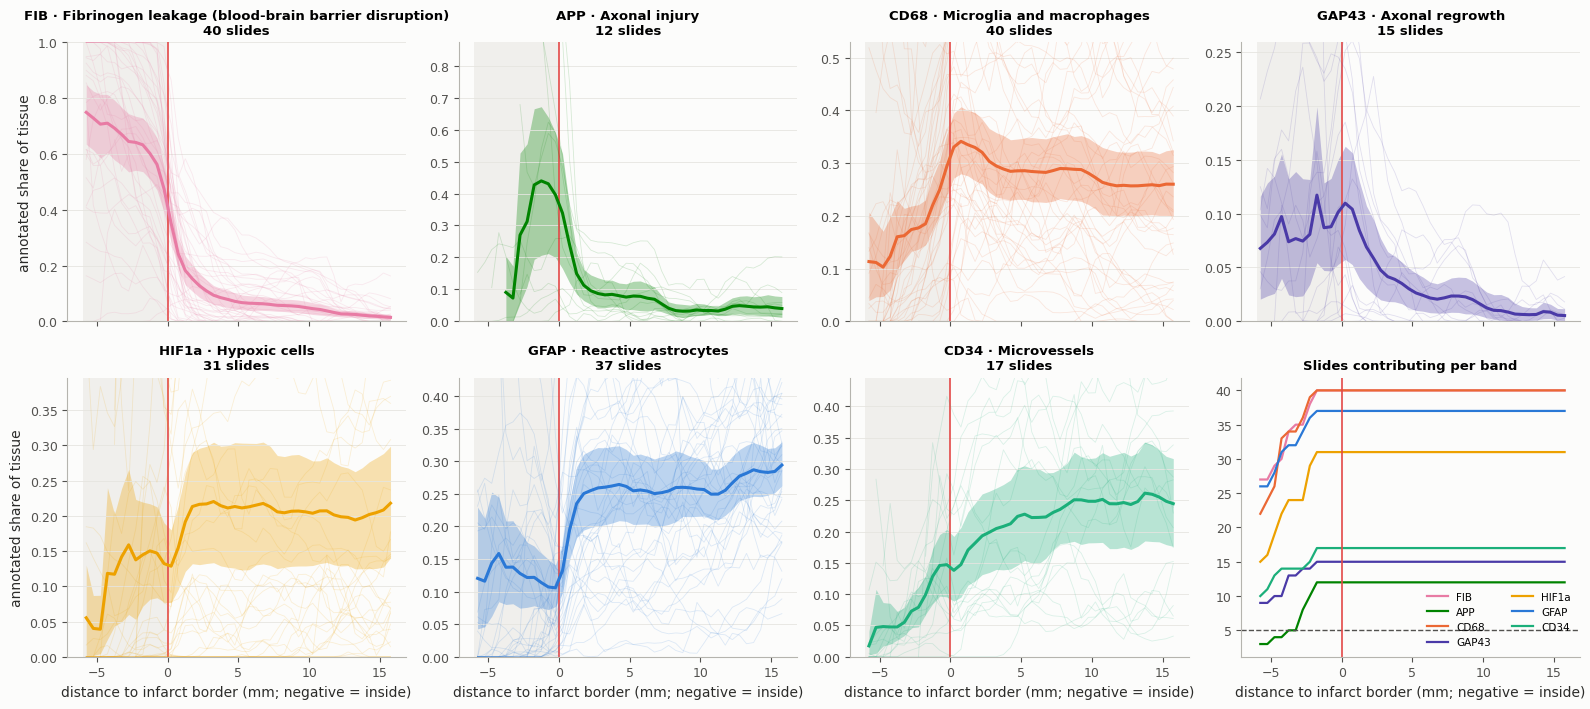

In [13]:
rng = np.random.default_rng(RANDOM_SEED)
summary = {}
for m in IHC_MARKERS:
    M = np.stack(pairs[pairs.marker == m].profile.to_numpy())
    n = np.isfinite(M).sum(axis=0)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        boot = np.nanmean(M[rng.integers(0, len(M), size=(N_BOOTSTRAP, len(M)))], axis=1)
        mean = np.nanmean(M, axis=0)
        lo, hi = np.nanpercentile(boot, [2.5, 97.5], axis=0)
    ok = n >= MIN_SLIDES_PER_BAND
    summary[m] = {"matrix": M, "mean": np.where(ok, mean, np.nan), "lo": np.where(ok, lo, np.nan),
                  "hi": np.where(ok, hi, np.nan), "n": n}

fig, axes = plt.subplots(2, 4, figsize=(16, 7.2), sharex=True)
for ax, m in zip(axes.ravel(), IHC_MARKERS):
    s, color = summary[m], du.MARKER_COLORS[m]
    ax.axvspan(BAND_EDGES_MM[0], 0, color="#f0efec", lw=0, zorder=0)
    ax.axvline(0, color=du.INFARCT_COLOR, lw=1.2)
    for row in s["matrix"]:
        ax.plot(BAND_MID, row, color=color, lw=0.6, alpha=0.15)
    ax.fill_between(BAND_MID, s["lo"], s["hi"], color=color, alpha=0.3, lw=0)
    ax.plot(BAND_MID, s["mean"], color=color, lw=2.2)
    ax.set_ylim(0, min(1, np.nanmax(s["hi"]) * 1.3))
    ax.set_title(f"{m} · {MARKERS[m]['target']}\n{len(s['matrix'])} slides", fontsize=9.5)
    ax.grid(axis="y")
ax = axes.ravel()[-1]
for m in IHC_MARKERS:
    ax.plot(BAND_MID, summary[m]["n"], color=du.MARKER_COLORS[m], lw=1.6, label=m)
ax.axhline(MIN_SLIDES_PER_BAND, ls="--", color="#52514e", lw=1)
ax.axvline(0, color=du.INFARCT_COLOR, lw=1.2)
ax.set_title("Slides contributing per band", fontsize=9.5)
ax.legend(fontsize=7.5, ncol=2)
for ax in axes[1]:
    ax.set_xlabel("distance to infarct border (mm; negative = inside)")
for ax in axes[:, 0]:
    ax.set_ylabel("annotated share of tissue")
plt.tight_layout()
plt.show()

Each panel shows individual slides (thin lines), the mean (thick line) and its 95% bootstrap interval. The grey background is the inside of the infarct. The table below condenses the profiles into four zones and the distance of maximal coverage.

In [14]:
zones = {"core (< -1 mm)": BAND_MID < -1, "border (±1 mm)": np.abs(BAND_MID) <= 1,
         "near (1-4 mm)": (BAND_MID > 1) & (BAND_MID <= 4), "far (10-16 mm)": BAND_MID >= 10}
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    zone_table = pd.DataFrame({z: [np.nanmean(summary[m]["mean"][k]) for m in IHC_MARKERS] for z, k in zones.items()},
                              index=IHC_MARKERS)
zone_table["peak (mm)"] = [BAND_MID[np.nanargmax(summary[m]["mean"])] for m in IHC_MARKERS]
zone_table["slides"] = [len(summary[m]["matrix"]) for m in IHC_MARKERS]
zone_table.sort_values("peak (mm)")

,core (< -1 mm),border (±1 mm),near (1-4 mm),far (10-16 mm),peak (mm),slides
FIB,0.68,0.41,0.13,0.03,-5.75,40
GAP43,0.08,0.10,0.06,0.01,-1.75,15
APP,0.27,0.35,0.10,0.04,-1.25,12
CD68,0.15,0.30,0.31,0.26,0.75,40
HIF1a,0.11,0.14,0.21,0.20,3.25,31
CD34,0.06,0.14,0.19,0.25,13.75,17
GFAP,0.13,0.13,0.25,0.27,15.75,37


**Reading the profiles.** Three spatial patterns stand out.

1. **Concentrated in the core: fibrinogen.** About 70% of the tissue deep inside the infarct is annotated, falling to about 13% within 4 mm of the border and to a few per cent far away. This fits plasma fibrinogen leaking through the damaged blood–brain barrier of the infarcted tissue.
2. **At the border: APP, GAP43 and CD68.** Axonal injury (APP) peaks about 1 mm *inside* the border. GAP43, a marker of axonal regrowth, is found mainly inside and at the border, at low coverage. CD68 peaks just *outside* the border, at about +1 mm, and stays high across the section, because microglia and macrophages are annotated widely.
3. **Depleted inside, higher outside: HIF1α, GFAP and CD34.** HIF1α coverage rises within about 3 mm outside the border and then levels off. GFAP and CD34 rise steadily with distance, so their maxima lie at the edge of the analysed range: there is no peri-infarct maximum, only depletion inside the infarct.

**Limits.** Distances are measured within each section plane. The infarct outline comes from an H&E section up to `MAX_INFARCT_GAP_UM` away. Slides of the same block are not independent, so the bootstrap intervals are optimistic. This is a single case.

## Summary

| Task | Call |
|---|---|
| All annotated sections of a marker or the infarct in a block | `AnnotationSeries(block, marker).load()` |
| Area per section and class | `.table()` |
| Volume between sections | `.volume_mm3()` |
| Stacked masks on a common grid | `.to_stack(region)` |
| Interpolated volume and 3D surface | `.interpolate(region)`, `.to_mesh(region)` |
| Tissue area of a section | `SlideHelper.get_tissue_area_mm2(section)` |
| Distance to the infarct on any slide | `SectionAnnotation.distance_map(region)` |

**Next:** `mri_reference_space.ipynb` relates these histological measurements to the lesion seen on MRI.